# Gamma Recovery — Triaxial NFW Lensing Test

Generates 500 mock clusters with a known pivot–magnitude-gap power-law index γ,
simulates the full weak-lensing signal using **triaxial NFW shear** (random CDM-like
axis ratios + isotropic line-of-sight orientations), and tests whether the destacking
likelihood recovers γ from per-cluster ΔΣ profiles measured through a metacal-format
source catalog.

The fitting model is still **spherical NFW** — the test probes whether triaxiality
biases the gamma recovery when clusters have random orientations.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting import run_sampler

from xlensing.sims import (
    make_simple_random_cat,
    equatorial_to_polar,
    add_shears,
    r_vir, NFW_delta_c, rhoM, gNFW,
    project_ellipsoid,
)
from xlensing.data import sigmacrit as sc_data
from xlensing.cosmo import DA
import ngmix

gNFW_vec = np.vectorize(gNFW)

try:
    from tqdm.auto import trange
except ImportError:
    def trange(n, **kwargs): return range(n)

## Parameters

In [ ]:
N_CLUSTERS   = 500       # number of clusters
TRUE_GAMMA   = 1.0       # the parameter to recover
RADII        = np.logspace(-0.6, 0.6, 8)   # projected radii [Mpc]
SEED         = 42

# ── Galaxy survey parameters (matching triaxial_shear_demo.ipynb) ──
DENSITY      = 30        # make_simple_random_cat density param → ~7.5 gal/arcmin² effective
WIDTH_RAD    = 0.006     # field half-width [rad] ≈ ±20 arcmin
                         # gives ~3 Mpc physical radius at z=0.2 (our min cluster z)
Z_SRC_RANGE  = (0.4, 1.5)
SHAPE_NOISE  = 0.25      # per-component rms (GPriorBA sigma)
NOISE_FLOOR_COV = 1e4    # [M_sun/pc²]² assigned to empty radial bins

# Bin limits
log_r = np.log10(RADII)
dlog  = np.diff(log_r)[0]
edges = np.logspace(log_r[0] - dlog/2, log_r[-1] + dlog/2, len(RADII) + 1)
bin_limits = np.column_stack([edges[:-1], edges[1:]])

## 1 — Generate truth catalog and save to FITS

In [ ]:
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range=(0.2, 0.6),     # avoid very low-z clusters where field radius is too small
    logM_range=(13.5, 15.0),
    delta_m_gamma=TRUE_GAMMA,
    scatter_logc=0.0,        # zero scatter: isolates triaxiality as the only extra signal
    seed=SEED,
)

truth.write('truth_catalog.fits', overwrite=True)
print(f'Saved {N_CLUSTERS} clusters  |  true γ = {TRUE_GAMMA}')
truth[:5]

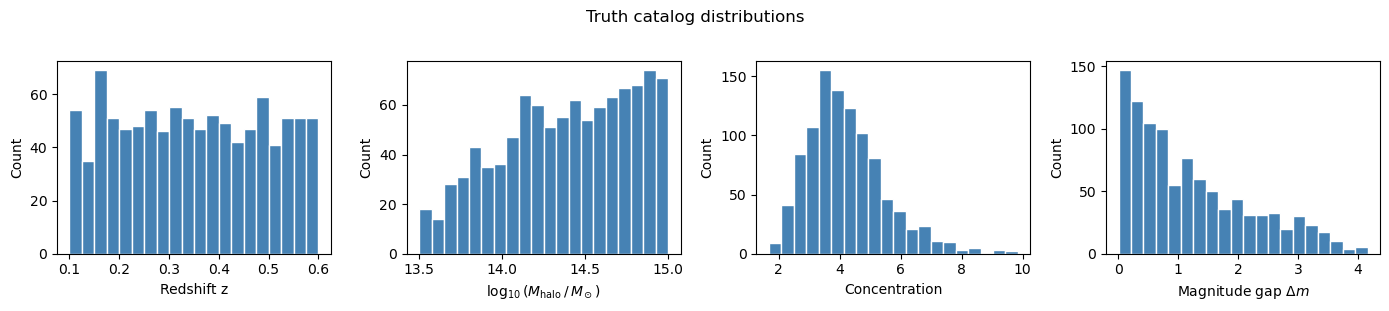

In [4]:
# Quick look at the truth distributions
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

axes[0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Redshift z')

axes[1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

axes[2].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[2].set_xlabel('Concentration')

dm = truth['delta_m']
axes[3].hist(dm[~np.isnan(dm)], bins=20, color='steelblue', edgecolor='white')
axes[3].set_xlabel(r'Magnitude gap $\Delta m$')

for ax in axes:
    ax.set_ylabel('Count')
plt.suptitle('Truth catalog distributions', y=1.02)
plt.tight_layout()
plt.show()

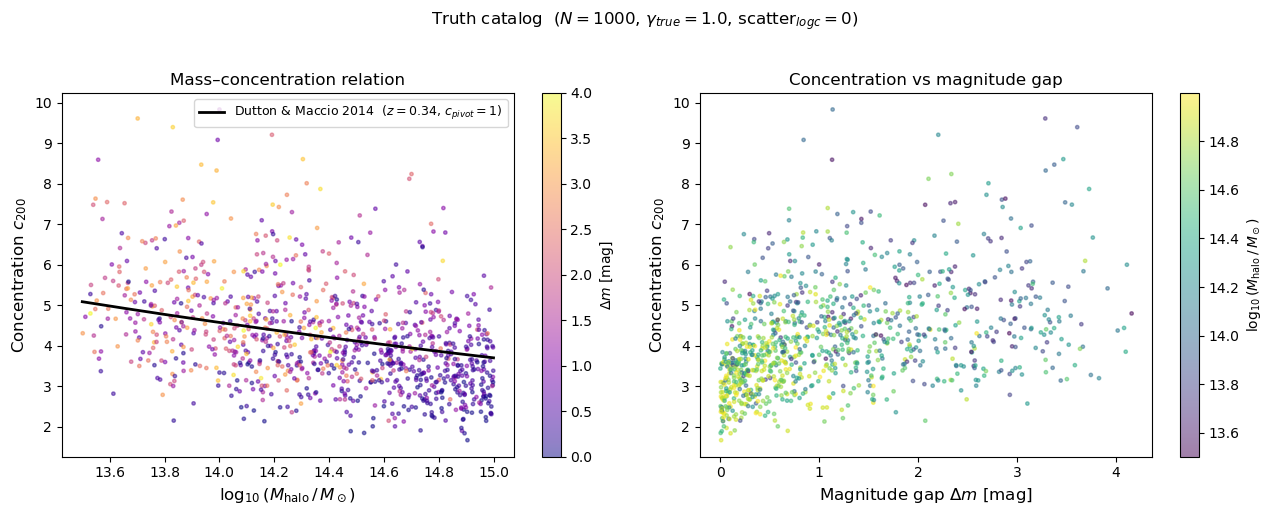

In [5]:
from destacking.relations import c_DuttonMaccio

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: M–c relation ---
ax = axes[0]
sc = ax.scatter(
    np.log10(truth['M_halo']), truth['concentration'],
    c=truth['delta_m'], cmap='plasma', s=6, alpha=0.5, vmin=0, vmax=4,
    rasterized=True,
)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')

z_med = float(np.median(truth['z']))
M_curve = np.logspace(13.5, 15.0, 200)
C_curve = c_DuttonMaccio(z_med * np.ones(200), M_curve)
ax.plot(np.log10(M_curve), C_curve, 'k-', lw=2,
        label=rf'Dutton & Maccio 2014  ($z={z_med:.2f}$, $c_{{pivot}}=1$)')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title('Mass–concentration relation', fontsize=12)
ax.legend(fontsize=9)

# --- Panel 2: c vs Δm ---
ax = axes[1]
sc2 = ax.scatter(
    truth['delta_m'], truth['concentration'],
    c=np.log10(truth['M_halo']), cmap='viridis', s=6, alpha=0.5,
    rasterized=True,
)
plt.colorbar(sc2, ax=ax, label=r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

ax.set_xlabel(r'Magnitude gap $\Delta m$ [mag]', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(r'Concentration vs magnitude gap', fontsize=12)

plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, $\gamma_{{true}}={TRUE_GAMMA}$, scatter$_{{logc}}=0$)',
    y=1.02, fontsize=12,
)
plt.tight_layout()
plt.show()

## 2 — Triaxial shapes and projected ellipses

Each cluster is assigned a random CDM-like triaxial shape and a random isotropic
line-of-sight direction.  `project_ellipsoid` computes the Schur complement of the
3D shape matrix to obtain the projected semi-axes (q_maj, q_min) and position angle pa.

In [ ]:
rng_tri = np.random.default_rng(SEED + 10)

# Virial radius for each cluster (used as major-axis scale)
r_vir_vals = np.array([r_vir(float(z), float(M))
                        for z, M in zip(truth['z'], truth['M_halo'])])

# CDM-like axis ratios: b/a ∈ (0.5, 1),  c/a ∈ (0.3, b/a)
q_ba = rng_tri.uniform(0.5, 1.0, N_CLUSTERS)
q_ca = rng_tri.uniform(0.3, q_ba)   # ensures c/a ≤ b/a element-wise

# Isotropic random line-of-sight directions: cos(θ) ~ U(0,1), φ ~ U(0,2π)
theta_los_arr = np.arccos(rng_tri.uniform(0.0, 1.0, N_CLUSTERS))
phi_los_arr   = rng_tri.uniform(0.0, 2 * np.pi, N_CLUSTERS)

# Project each 3D ellipsoid → projected sky ellipse
print("Projecting triaxial ellipsoids...")
q_maj_arr = np.zeros(N_CLUSTERS)
q_min_arr = np.zeros(N_CLUSTERS)
pa_arr    = np.zeros(N_CLUSTERS)
for i in range(N_CLUSTERS):
    a = r_vir_vals[i]
    b, c = q_ba[i] * a, q_ca[i] * a
    q_maj_arr[i], q_min_arr[i], pa_arr[i] = project_ellipsoid(
        a, b, c, theta_los_arr[i], phi_los_arr[i]
    )

print(f"Projected axis ratio q_min/q_maj:  "
      f"median={np.median(q_min_arr/q_maj_arr):.2f}, "
      f"range [{(q_min_arr/q_maj_arr).min():.2f}, {(q_min_arr/q_maj_arr).max():.2f}]")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(q_ba, bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('b/a  (intermediate/major)')
axes[1].hist(q_ca, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('c/a  (minor/major)')
axes[2].hist(q_min_arr / q_maj_arr, bins=20, color='tomato', edgecolor='white')
axes[2].set_xlabel('projected $q_{\\rm min}/q_{\\rm maj}$')
for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Triaxial shape distributions', y=1.02)
plt.tight_layout(); plt.show()

## 3 — Simulate triaxial NFW lensing measurements

For each cluster we:
1. Select background galaxies from a shared metacal-format source field.
2. Apply the cluster's triaxial NFW shear (vectorised, using pre-computed geometry).
3. Add realistic shape noise via `GPriorBA(σ=0.25)`.
4. Estimate ΔΣ(R) per radial bin with a direct metacal-weighted estimator.
5. Assign diagonal shape-noise covariance; empty bins get a large noise floor so they
   are effectively excluded from the likelihood.

The **cluster observables** (z, Λ, Δm) come from `make_test_data` (Lambda sampling only).

In [ ]:
# ── Cluster observable table (z, Lambda, delta_m) — use make_test_data for Lambda sampling ──
cluster_obs, _, _ = make_test_data(truth, RADII, fractional_noise=0.2, seed=SEED + 1)

print(f'Observable table: {cluster_obs.colnames}')
print(f'Richness range:   {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
cluster_obs[:5]

In [ ]:
# ── Shared background galaxy field (positions/z fixed; shapes drawn fresh per cluster) ──
rng_base = np.random.default_rng(99)
base_cat  = make_simple_random_cat(DENSITY, WIDTH_RAD, Z_SRC_RANGE, shape_noise=0.0, seed=0).T
RA_ALL    = base_cat[:, 0]
DEC_ALL   = base_cat[:, 1]
Z_ALL     = base_cat[:, 2]
N_GALS    = len(base_cat)

# Lognormal size distribution → diagonal metacal response R11 = R22 = 1 − (size/scale)²
sizes  = rng_base.lognormal(mean=np.log(0.5), sigma=0.5, size=N_GALS)
R_RESP = np.clip(1.0 - (sizes / 1.5) ** 2, 0.05, 0.99)

# Pre-compute angular geometry (cluster always at RA=DEC=0)
sep_all, theta_all = equatorial_to_polar(0., 0., RA_ALL, DEC_ALL)

print(f"Source field: {N_GALS} galaxies, half-width {WIDTH_RAD} rad")

In [ ]:
%%time
shape_prior = ngmix.priors.shape.GPriorBA(sigma=SHAPE_NOISE, rng=np.random.default_rng(1))

N_BINS       = len(RADII)
data_vectors = np.zeros((N_CLUSTERS, N_BINS))
cov_matrices = np.full((N_CLUSTERS, N_BINS, N_BINS), 0.)   # filled below

for i in trange(N_CLUSTERS, desc='Triaxial lensing'):
    z_i = float(truth['z'][i])
    M_i = float(truth['M_halo'][i])
    c_i = float(truth['concentration'][i])

    # ── Background selection ──────────────────────────────────────────────
    DA_i     = DA(0, z_i)
    bg_mask  = (sep_all < WIDTH_RAD) & (Z_ALL > 1.1 * z_i + 0.2)
    bg_idx   = np.where(bg_mask)[0]
    n_bg     = len(bg_idx)

    # Initialise with large noise (empty bins excluded from likelihood)
    np.fill_diagonal(cov_matrices[i], NOISE_FLOOR_COV)

    if n_bg < 20:
        continue

    # ── Background galaxy properties ──────────────────────────────────────
    Z_bg    = Z_ALL[bg_idx]
    THETA_i = theta_all[bg_idx]
    sep_i   = sep_all[bg_idx]
    DX_bg   = DA_i * sep_i * np.sin(THETA_i)   # east offset [Mpc]
    DY_bg   = DA_i * sep_i * np.cos(THETA_i)   # north offset [Mpc]
    R_bg    = sep_i * DA_i                       # physical radius [Mpc]
    R11_bg  = R_RESP[bg_idx]

    # Critical surface density (single vectorised astropy call per cluster)
    sigcrit_i = sc_data(z_i, Z_bg) / 1e12   # [M_sun / pc²]

    # ── NFW parameters ────────────────────────────────────────────────────
    rs_i  = r_vir(z_i, M_i) / c_i
    amp_i = rs_i * NFW_delta_c(c_i) * rhoM(z_i)   # [M_sun / Mpc²]

    # ── Triaxial effective radius and shear direction ──────────────────────
    q_maj_i, q_min_i, pa_i = q_maj_arr[i], q_min_arr[i], pa_arr[i]
    u = DX_bg * np.sin(pa_i) + DY_bg * np.cos(pa_i)
    v = DX_bg * np.cos(pa_i) - DY_bg * np.sin(pa_i)
    r_eff   = np.sqrt((u / q_maj_i) ** 2 + (v / q_min_i) ** 2) * np.sqrt(q_maj_i * q_min_i)
    gx      = np.sin(pa_i) * u / q_maj_i ** 2 + np.cos(pa_i) * v / q_min_i ** 2
    gy      = np.cos(pa_i) * u / q_maj_i ** 2 - np.sin(pa_i) * v / q_min_i ** 2
    phi_eff = np.arctan2(gx, gy)

    # Shear magnitude (same NFW profile, circularised radius)
    x_arr  = np.maximum(r_eff, 1e-4) / rs_i
    gammat = amp_i / (sigcrit_i * 1e12) * gNFW_vec(x_arr)
    g_tri  = gammat * np.exp(2j * phi_eff)

    # ── Shape noise + reduced shear ───────────────────────────────────────
    e1_int, e2_int = shape_prior.sample2d(n_bg)
    e_obs  = add_shears(e1_int + 1j * e2_int, g_tri)

    # Tangential ellipticity (sims.py theta convention → positive et for NFW)
    cos2t = np.cos(2 * THETA_i)
    sin2t = np.sin(2 * THETA_i)
    et    = e_obs.real * cos2t + e_obs.imag * sin2t
    M_bg  = R11_bg - 1   # metacal multiplicative bias

    # ── ΔΣ estimator per radial bin ───────────────────────────────────────
    in_bin = (R_bg[:, None] > bin_limits[:, 0]) & (R_bg[:, None] < bin_limits[:, 1])
    for b in range(N_BINS):
        mask_b = in_bin[:, b]
        n_b    = mask_b.sum()
        if n_b < 5:
            continue
        s = sigcrit_i[mask_b]; e = et[mask_b]; m = M_bg[mask_b]
        data_vectors[i, b] = (e / s).sum() / ((1 + m) / s ** 2).sum()
        # Diagonal shape-noise covariance
        sigma_dsigma = SHAPE_NOISE * s.mean() / np.sqrt(n_b)
        cov_matrices[i, b, b] = sigma_dsigma ** 2

print(f"\nData generated. Non-empty bins per cluster: "
      f"{(np.diagonal(cov_matrices, axis1=1, axis2=2) < NOISE_FLOOR_COV).sum(1).mean():.1f} / {N_BINS}")

In [ ]:
# Sanity check — plot six example profiles
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    # Only show bins with real data (not the noise-floor-filled ones)
    real_mask = errs < np.sqrt(NOISE_FLOOR_COV)
    ax.errorbar(RADII[real_mask], data_vectors[i, real_mask], yerr=errs[real_mask],
                fmt='o', markersize=4, capsize=4, color='steelblue')
    ax.set_xscale('log')
    ax.set_yscale('log')
    dm_str = f'{cluster_obs["delta_m"][i]:.2f}' if np.isfinite(cluster_obs['delta_m'][i]) else 'nan'
    ax.set_title(
        f'z={cluster_obs["z"][i]:.2f}  '
        rf'$\lambda$={cluster_obs["Lambda"][i]:.0f}  '
        rf'$\Delta m$={dm_str}  '
        rf'$q$={q_min_arr[i]/q_maj_arr[i]:.2f}',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle('Sample ΔΣ profiles — triaxial lensing pipeline', y=1.01)
plt.tight_layout()
plt.show()

## 4 — Run the sampler

Fits γ and log_M_norm jointly against the triaxially-simulated ΔΣ profiles.
The forward model uses spherical NFW — any bias here is due to triaxiality.

In [8]:
sampler = run_sampler(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    gamma_range=(0.0, 3.0),
    n_live=500,
    verbose=True,
    pool=15,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 19     | 1        | 4        | 16695    | N/A    | 10011 | -30275.06


## 5 — Posterior and recovery plot

In [9]:
points, log_w, log_l = sampler.posterior()
gamma_samples = points[:, 0]
weights       = np.exp(log_w - log_w.max())   # numerically stable normalisation
weights      /= weights.sum()


def weighted_quantile(values, quantiles, weights):
    """Weighted quantiles via sorted cumulative sum."""
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w) / np.sum(w)
    return np.interp(quantiles, cumw, v)


glo, gmd, ghi = weighted_quantile(gamma_samples, [0.16, 0.50, 0.84], weights)
print(f'True γ  : {TRUE_GAMMA}')
print(f'Recovered: {gmd:.3f}  −{gmd - glo:.3f}  +{ghi - gmd:.3f}')

True γ  : 1.0
Recovered: 1.037  −0.038  +0.037


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.hist(
    gamma_samples, weights=weights, bins=40, density=True,
    color='steelblue', alpha=0.65, edgecolor='white', label='Posterior',
)
ax.axvspan(
    glo, ghi, alpha=0.20, color='steelblue',
    label=rf'68% CI  [{glo:.3f}, {ghi:.3f}]',
)
ax.axvline(gmd,       color='steelblue', lw=1.5, ls='-',
           label=rf'Median $\hat{{\gamma}}$ = {gmd:.3f}')
ax.axvline(TRUE_GAMMA, color='crimson',   lw=2.0, ls='--',
           label=rf'True $\gamma$ = {TRUE_GAMMA}')

ax.set_xlabel(r'$\gamma$  (pivot–magnitude-gap index)', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title(
    rf'Recovery of $\gamma$ from {N_CLUSTERS} triaxial clusters'
    '\n(spherical NFW model, full lensing pipeline)',
    fontsize=12,
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f'gamma_posterior_triaxial_{TRUE_GAMMA}.png', dpi=150)
plt.show()

bias = abs(gmd - TRUE_GAMMA) / ((ghi - glo) / 2)
print(f"\nBias relative to 68% CI width: {bias:.2f}σ"
      f"  ({'consistent' if bias < 2 else 'BIASED'} with true γ)")